# S03-02 — RQ03 e RQ04: estatística descritiva (#168)

Taxa de falha de mudanças (RQ03) e tempo de recuperação (RQ04) dos 500 repositórios da amostra final.

- Fonte principal: `entregas/s02-03-dataset-500-final/dataset-500.csv` (contrato `lab03-dataset-v1`, janela de 2025-10-01 a 2026-10-01, exclusivo).
- Episódios de recuperação por repositório: `dados/rq04_episodios_500.csv`, exportado com `python -m pipeline.descritiva` de `processed/amostra-final-500/tempo_recuperacao.json` do pacote `entregas/dados-brutos-500/` (SHA-256 da origem em `dados/rq04_episodios_500.json`). Os valores de recuperação desse JSON coincidem com os do CSV final, e os totais de episódios com a auditoria em `validacao.json`.
- CFR (a): falhas / (falhas + sucessos) nos runs válidos. CFR (b): releases corretivas / releases estáveis, pela heurística v1 da #161, **ainda sem a validação contra os rótulos humanos (#162)**.
- Cada métrica é resumida só pelos valores válidos; ausências não viram zero. Quartis por interpolação linear; IQR = Q3 − Q1.
- Saídas: `tabelas/` (CSV) e `figuras/` (PNG). Reexecute com *Run All* a partir desta pasta.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from pipeline.classificacao import DIA, HORA, SEMANA
from pipeline.descritiva import carregar_dataset, comparar_variantes, pares_variantes, tabela_resumo

DATASET = RAIZ / "entregas" / "s02-03-dataset-500-final" / "dataset-500.csv"
EPISODIOS = Path("dados") / "rq04_episodios_500.csv"
FIGURAS, TABELAS = Path("figuras"), Path("tabelas")
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
TINTA, TINTA_CLARA, CORTE = "#333333", "#999999", "#777777"
CLASSES = ["Elite", "High", "Medium", "Low"]

dados = carregar_dataset(DATASET)
episodios = pd.read_csv(EPISODIOS)
assert set(episodios["id"]) == set(dados["id"]), "episódios e dataset com IDs diferentes"
pd.options.display.float_format = "{:,.3f}".format
print(f"{len(dados)} repositórios; janela {dados.janela_inicio.iloc[0]} a {dados.janela_fim_exclusivo.iloc[0]}")

500 repositórios; janela 2025-10-01T00:00:00Z a 2026-10-01T00:00:00Z


## RQ03 — Taxa de falha de mudanças

As duas variantes em fração [0, 1]. Cortes DORA (inclusivos): Elite ≤ 0,15, High ≤ 0,30, Medium ≤ 0,45.

In [2]:
rq03 = tabela_resumo(dados, {"CFR (a) runs": "cfr_a", "CFR (b) releases corretivas": "cfr_b"})
rq03.to_csv(TABELAS / "rq03_resumo.csv", index=False)
rq03

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,CFR (a) runs,500,0,0.000,0.023,0.053,0.118,0.095,1.000,0.099
1,CFR (b) releases corretivas,498,2,0.000,0.200,0.440,0.727,0.527,1.000,0.468


### Comparação das variantes (a) e (b)

Pares do mesmo repositório. Diferença = (a) − (b); razão = (a) / (b), nula quando (b) = 0. A hipótese da RQ03 espera valores diferentes entre as variantes e classes DORA diferentes para uma parcela relevante dos repositórios.

In [3]:
pares = pares_variantes(dados, "cfr_a", "cfr_b")
pares.to_csv(TABELAS / "rq03_pares_variantes.csv", index=False)
comparacao = pd.Series(comparar_variantes(pares), name="valor", dtype=object).to_frame()

classes = dados.dropna(subset=["classe_cfr_a", "classe_cfr_b"])
cruzada = pd.crosstab(pd.Categorical(classes["classe_cfr_a"], CLASSES), pd.Categorical(classes["classe_cfr_b"], CLASSES),
                      rownames=["classe CFR (a)"], colnames=["classe CFR (b)"], dropna=False)
mesma_classe = int((classes["classe_cfr_a"] == classes["classe_cfr_b"]).sum())
comparacao.loc["mesma_classe"] = mesma_classe
comparacao.loc["percentual_mesma_classe"] = 100 * mesma_classe / len(classes)
comparacao.to_csv(TABELAS / "rq03_comparacao_variantes.csv")
cruzada.to_csv(TABELAS / "rq03_classes_a_x_b.csv")
display(comparacao)
cruzada

,valor
n_pares,498
a_maior,68
iguais,5
a_menor,425
mediana_diferenca,-0.348
mediana_razao,0.122
mesma_classe,104
percentual_mesma_classe,20.884


classe CFR (b),Elite,High,Medium,Low
classe CFR (a),,,,
Elite,82,73,55,193
High,9,12,8,33
Medium,2,3,2,11
Low,1,3,3,8


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_10196\4155279817.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([cfr_a, cfr_b], vert=False, widths=0.5, tick_labels=["(a) runs", "(b) releases\ncorretivas"],


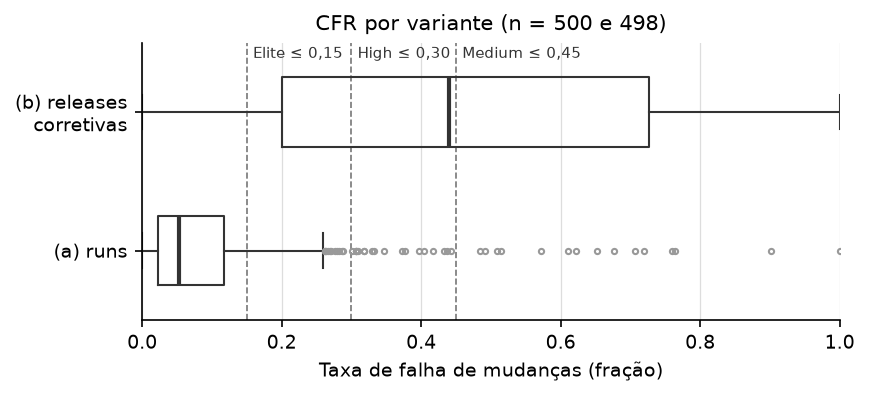

In [4]:
cortes_cfr = {"Elite": 0.15, "High": 0.30, "Medium": 0.45}
cfr_a, cfr_b = dados["cfr_a"].dropna(), dados["cfr_b"].dropna()

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.boxplot([cfr_a, cfr_b], vert=False, widths=0.5, tick_labels=["(a) runs", "(b) releases\ncorretivas"],
           flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": "none", "markeredgecolor": TINTA_CLARA},
           medianprops={"color": TINTA, "linewidth": 2}, boxprops={"color": TINTA}, whiskerprops={"color": TINTA},
           capprops={"color": TINTA})
for rotulo, x in cortes_cfr.items():
    ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.8, zorder=0)
    ax.annotate(f"{rotulo} ≤ {x:.2f}".replace(".", ","), (x, 1), xycoords=("data", "axes fraction"),
                xytext=(3, -2), textcoords="offset points", va="top", fontsize=7, color=TINTA)
ax.set_xlim(0, 1)
ax.set_xlabel("Taxa de falha de mudanças (fração)")
ax.grid(axis="y", visible=False)
ax.set_title(f"CFR por variante (n = {len(cfr_a)} e {len(cfr_b)})", fontsize=10)
fig.savefig(FIGURAS / "rq03_cfr_variantes.png")
plt.show()

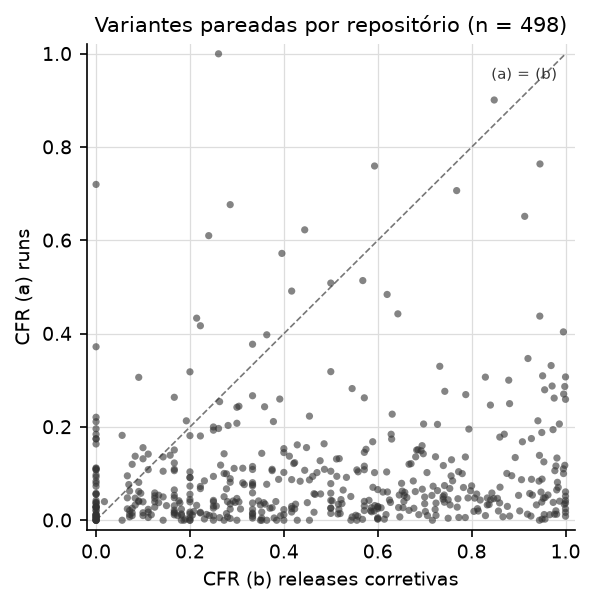

In [5]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot([0, 1], [0, 1], color=CORTE, linestyle="--", linewidth=0.8, zorder=1)
ax.annotate("(a) = (b)", (1, 1), xytext=(-4, -12), textcoords="offset points", ha="right", fontsize=7, color=TINTA)
ax.scatter(pares["cfr_b"], pares["cfr_a"], s=12, color=TINTA, alpha=0.6, edgecolor="none", zorder=2)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("CFR (b) releases corretivas")
ax.set_ylabel("CFR (a) runs")
ax.set_title(f"Variantes pareadas por repositório (n = {len(pares)})", fontsize=10)
fig.savefig(FIGURAS / "rq03_cfr_pareado.png")
plt.show()

## RQ04 — Tempo de recuperação

Valor do repositório: mediana, em horas, dos episódios recuperados (do primeiro run com falha ao sucesso seguinte). Episódios censurados à direita (sem sucesso até o fim da janela) e sequências censuradas à esquerda (falhas sem sucesso anterior observado) ficam fora da mediana. Cortes DORA: Elite < 1 h, High < 24 h, Medium < 168 h.

In [6]:
dados["tempo_recuperacao_dias"] = dados["tempo_recuperacao"] / DIA
rq04 = tabela_resumo(dados, {"Recuperação (horas)": "tempo_recuperacao", "Recuperação (dias)": "tempo_recuperacao_dias"})
rq04.to_csv(TABELAS / "rq04_resumo.csv", index=False)
rq04

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,Recuperação (horas),469,31,0.065,1.084,2.601,7.221,6.137,692.980,14.902
1,Recuperação (dias),469,31,0.003,0.045,0.108,0.301,0.256,28.874,0.621


### Episódios censurados

Percentual de censura à direita sobre o total de episódios, no agregado e por repositório. Sequências censuradas à esquerda não são episódios e são contadas à parte.

In [7]:
total = episodios[["total_episodios", "episodios_recuperados", "episodios_censurados", "sequencias_censura_esquerda"]].sum()
sem_recuperacao = episodios[episodios["episodios_recuperados"] == 0]
censura = pd.Series({
    "episodios_total": total["total_episodios"],
    "episodios_recuperados": total["episodios_recuperados"],
    "episodios_censurados_direita": total["episodios_censurados"],
    "percentual_censurados": 100 * total["episodios_censurados"] / total["total_episodios"],
    "repositorios_com_censura_direita": int((episodios["episodios_censurados"] > 0).sum()),
    "sequencias_censura_esquerda": total["sequencias_censura_esquerda"],
    "repositorios_com_censura_esquerda": int((episodios["sequencias_censura_esquerda"] > 0).sum()),
    "repositorios_sem_episodio_recuperado": len(sem_recuperacao),
    "dos_quais_sem_nenhum_episodio": int((sem_recuperacao["total_episodios"] == 0).sum()),
}, name="valor", dtype=object).to_frame()
censura.to_csv(TABELAS / "rq04_censura.csv")
por_repositorio = tabela_resumo(episodios.assign(percentual=100 * episodios["proporcao_censurados"]),
                                {"Censurados por repositório (%)": "percentual"})
por_repositorio.to_csv(TABELAS / "rq04_censura_por_repositorio.csv", index=False)
display(censura)
por_repositorio

,valor
episodios_total,92890
episodios_recuperados,92560
episodios_censurados_direita,330
percentual_censurados,0.355
repositorios_com_censura_direita,167
sequencias_censura_esquerda,683
repositorios_com_censura_esquerda,274
repositorios_sem_episodio_recuperado,31
dos_quais_sem_nenhum_episodio,29


,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,Censurados por repositório (%),471,29,0.000,0.000,0.000,0.717,0.717,100.000,2.205


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_10196\2527867724.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(rec, vert=False, widths=0.6,


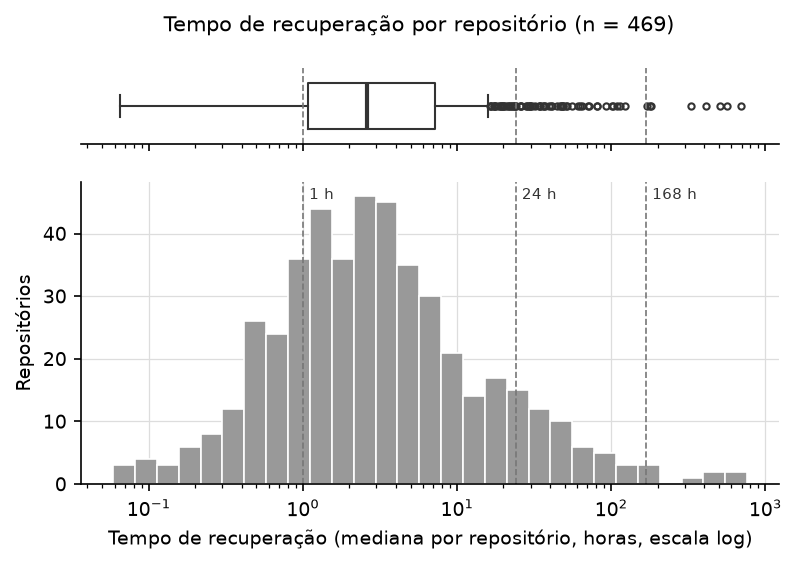

In [8]:
rec = dados["tempo_recuperacao"].dropna()
cortes_rec = {"1 h": HORA, "24 h": DIA, "168 h": SEMANA}
bins = np.logspace(np.log10(rec.min() * 0.9), np.log10(rec.max() * 1.1), 30)

fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(6, 3.6), height_ratios=[1, 4])
ax_box.boxplot(rec, vert=False, widths=0.6,
               flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "none", "markeredgecolor": TINTA},
               medianprops={"color": TINTA, "linewidth": 2}, boxprops={"color": TINTA}, whiskerprops={"color": TINTA},
               capprops={"color": TINTA})
ax_box.set_yticks([])
ax_box.grid(False)
ax_box.spines["left"].set_visible(False)
ax_hist.hist(rec, bins=bins, color=TINTA_CLARA, edgecolor="white", linewidth=0.8)
for rotulo, x in cortes_rec.items():
    for ax in (ax_box, ax_hist):
        ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.8)
    ax_hist.annotate(rotulo, (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -3),
                     textcoords="offset points", va="top", fontsize=7, color=TINTA)
ax_hist.set_xscale("log")
ax_hist.set_xlabel("Tempo de recuperação (mediana por repositório, horas, escala log)")
ax_hist.set_ylabel("Repositórios")
fig.suptitle(f"Tempo de recuperação por repositório (n = {len(rec)})", fontsize=10)
fig.savefig(FIGURAS / "rq04_tempo_recuperacao.png")
plt.show()

## Limitações

- A CFR (b) vem da heurística v1 (#161); precisão, recall e F1 contra os rótulos humanos são avaliados na #162. Os números da variante (b) podem mudar com o refinamento da #163.
- A CFR (a) conta falhas de CI, que incluem testes instáveis e erros de configuração, e não só falhas que chegariam ao usuário.
- O tempo de recuperação descreve só episódios recuperados; não é uma estimativa de sobrevivência e não corrige a censura.
- A amostra não é aleatória (ver o funil na metodologia), o que limita a generalização.
- A classificação DORA geral fica na S03-03 (#169).